In [78]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the AUC results
auc_df = pd.read_csv("auc_scores_with_rf_kappa_thresholding_detailed.csv")
auc_df["Random_AUCPR"] = auc_df["Total Actives Test"]/(auc_df["Total Inactives Test"] + auc_df["Total Actives Test"])

# Group by Task (Assay) and Feature Set to compute summary statistics
summary_stats = auc_df.groupby(["Task", "Feature Set"])["AUC"].agg(["mean", "std", "count"]).reset_index()


# Compare the overall performance across feature sets
overall_comparison = auc_df.groupby("Feature Set")["AUC"].agg(["mean", "std"]).reset_index()


In [79]:
auc_df

,Feature Set,Fold,Task,AUC,Optimal Threshold,Optimal Kappa,Kappa,Kappa @ 0.50,Balanced Accuracy,AUCPR,...,FN,Total Actives Train,Total Inactives Train,Total Compounds Train,Total Actives Test,Total Inactives Test,Total Compounds Test,Scrambled Kappa,Scrambled Balanced Accuracy,Random_AUCPR
0,CellCount,1,ADRA1A_Antagonist,0.482456,0.626263,0.255319,0.025729,-0.036690,0.509398,0.243797,...,13,28,112,140,14,57,71,-0.046426,0.460526,0.197183
1,CellCount,2,ADRA1A_Antagonist,0.636480,0.525253,0.068440,0.220183,0.114286,0.607143,0.497388,...,9,28,113,141,14,56,70,-0.114286,0.410714,0.200000
2,CellCount,3,ADRA1A_Antagonist,0.570791,0.555556,0.188383,0.015748,-0.073620,0.508929,0.253146,...,10,28,113,141,14,56,70,-0.073620,0.446429,0.200000
3,CellProfiler,1,ADRA1A_Antagonist,0.476190,0.333333,0.309623,-0.051513,-0.074800,0.474937,0.183223,...,12,28,112,140,14,57,71,-0.027001,0.491228,0.197183
4,CellProfiler,2,ADRA1A_Antagonist,0.614796,0.414141,0.109762,-0.027397,0.000000,0.491071,0.293329,...,14,28,113,141,14,56,70,0.000000,0.500000,0.200000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,CellCount,2,SF1_Antagonist,0.504274,0.505051,0.058082,-0.048150,-0.008252,0.456197,0.154916,...,8,24,145,169,13,72,85,-0.008252,0.491453,0.152941
140,CellCount,3,SF1_Antagonist,0.500000,0.000000,0.000000,0.000000,0.000000,0.500000,0.571429,...,0,25,145,170,12,72,84,0.000000,0.500000,0.142857
141,CellProfiler,1,SF1_Antagonist,0.735160,0.303030,0.212399,0.224250,0.000000,0.647260,0.282772,...,6,25,144,169,12,73,85,0.000000,0.500000,0.141176
142,CellProfiler,2,SF1_Antagonist,0.707265,0.272727,0.242347,0.339720,0.000000,0.675214,0.343196,...,7,24,145,169,13,72,85,0.000000,0.500000,0.152941


In [80]:
auc_df.Task.nunique()

24

In [81]:
auc_df.groupby(["Feature Set", "Task"]).mean().groupby(["Feature Set"]).mean()

,Fold,AUC,Optimal Threshold,Optimal Kappa,Kappa,Kappa @ 0.50,Balanced Accuracy,AUCPR,Sensitivity,Specificity,...,FN,Total Actives Train,Total Inactives Train,Total Compounds Train,Total Actives Test,Total Inactives Test,Total Compounds Test,Scrambled Kappa,Scrambled Balanced Accuracy,Random_AUCPR
Feature Set,,,,,,,,,,,,,,,,,,,,,
CellCount,2.0,0.524407,0.354377,0.070146,0.028785,0.004834,0.515394,0.317376,0.568001,0.462787,...,4.361111,22.5,141.583333,164.083333,11.25,70.791667,82.041667,-0.004186,0.495347,0.136755
CellProfiler,2.0,0.618041,0.255612,0.220253,0.147667,0.061472,0.573596,0.294071,0.349700,0.797491,...,7.263889,22.5,141.583333,164.083333,11.25,70.791667,82.041667,0.001558,0.500781,0.136755


In [82]:
auc_df.groupby(["Feature Set", "Task"]).mean().groupby(["Feature Set"]).std()

,Fold,AUC,Optimal Threshold,Optimal Kappa,Kappa,Kappa @ 0.50,Balanced Accuracy,AUCPR,Sensitivity,Specificity,...,FN,Total Actives Train,Total Inactives Train,Total Compounds Train,Total Actives Test,Total Inactives Test,Total Compounds Test,Scrambled Kappa,Scrambled Balanced Accuracy,Random_AUCPR
Feature Set,,,,,,,,,,,,,,,,,,,,,
CellCount,0.0,0.068625,0.217730,0.059008,0.063885,0.042186,0.039320,0.153361,0.295619,0.336582,...,3.058080,10.339643,12.047912,9.086408,5.169821,6.023956,4.543204,0.036923,0.046792,0.061153
CellProfiler,0.0,0.108168,0.080238,0.147023,0.177919,0.138924,0.092199,0.146749,0.170527,0.184671,...,3.822106,10.339643,12.047912,9.086408,5.169821,6.023956,4.543204,0.017205,0.006934,0.061153


In [83]:
df = auc_df
df

,Feature Set,Fold,Task,AUC,Optimal Threshold,Optimal Kappa,Kappa,Kappa @ 0.50,Balanced Accuracy,AUCPR,...,FN,Total Actives Train,Total Inactives Train,Total Compounds Train,Total Actives Test,Total Inactives Test,Total Compounds Test,Scrambled Kappa,Scrambled Balanced Accuracy,Random_AUCPR
0,CellCount,1,ADRA1A_Antagonist,0.482456,0.626263,0.255319,0.025729,-0.036690,0.509398,0.243797,...,13,28,112,140,14,57,71,-0.046426,0.460526,0.197183
1,CellCount,2,ADRA1A_Antagonist,0.636480,0.525253,0.068440,0.220183,0.114286,0.607143,0.497388,...,9,28,113,141,14,56,70,-0.114286,0.410714,0.200000
2,CellCount,3,ADRA1A_Antagonist,0.570791,0.555556,0.188383,0.015748,-0.073620,0.508929,0.253146,...,10,28,113,141,14,56,70,-0.073620,0.446429,0.200000
3,CellProfiler,1,ADRA1A_Antagonist,0.476190,0.333333,0.309623,-0.051513,-0.074800,0.474937,0.183223,...,12,28,112,140,14,57,71,-0.027001,0.491228,0.197183
4,CellProfiler,2,ADRA1A_Antagonist,0.614796,0.414141,0.109762,-0.027397,0.000000,0.491071,0.293329,...,14,28,113,141,14,56,70,0.000000,0.500000,0.200000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,CellCount,2,SF1_Antagonist,0.504274,0.505051,0.058082,-0.048150,-0.008252,0.456197,0.154916,...,8,24,145,169,13,72,85,-0.008252,0.491453,0.152941
140,CellCount,3,SF1_Antagonist,0.500000,0.000000,0.000000,0.000000,0.000000,0.500000,0.571429,...,0,25,145,170,12,72,84,0.000000,0.500000,0.142857
141,CellProfiler,1,SF1_Antagonist,0.735160,0.303030,0.212399,0.224250,0.000000,0.647260,0.282772,...,6,25,144,169,12,73,85,0.000000,0.500000,0.141176
142,CellProfiler,2,SF1_Antagonist,0.707265,0.272727,0.242347,0.339720,0.000000,0.675214,0.343196,...,7,24,145,169,13,72,85,0.000000,0.500000,0.152941


In [84]:
# How many times is CellProfiler 10% better AUCPR than Cell Count or the Random Model

# Find maximum AUCPR for CellCount and Random_AUCPR per task
cellcount_random_max = df[df["Feature Set"] == "CellCount"].groupby(["Task", "Fold"])[["AUCPR", "Random_AUCPR"]].max()
cellcount_random_max["Max_CellCount_Random_AUCPR"] = cellcount_random_max[["AUCPR", "Random_AUCPR"]].max(axis=1)

# Merge the maximum CellCount/Random_AUCPR back with CellProfiler data
cellprofiler_df = df[df["Feature Set"] == "CellProfiler"].merge(cellcount_random_max["Max_CellCount_Random_AUCPR"], on=["Task", "Fold"])

# Compare CellProfiler AUCPR with the max of CellCount/Random_AUCPR for each task
cellprofiler_df["Better_AUCPR"] = cellprofiler_df["AUCPR"] >= cellprofiler_df["Max_CellCount_Random_AUCPR"]*1.1

# Count how many times CellProfiler AUCPR is better per task
better_aucpr_counts_corrected = cellprofiler_df.groupby("Task")["Better_AUCPR"].sum()

better_aucpr_counts_corrected


Task
ADRA1A_Antagonist    1
ADRA2A_Antagonist    0
ADRA2B_Antagonist    0
CAR_Antagonist       1
ERa_Antagonist       2
ERb_Antagonist       1
GPR119_Antagonist    1
GR_Agonist           3
HCTR1_Antagonist     2
PPARa_Antagonist     0
PPARg_Antagonist     1
PR_Agonist           3
PR_Antagonist        1
PXR_Agonist          1
RARa_Antagonist      3
RARb_Antagonist      3
RARg_Antagonist      2
RORa_Antagonist      1
RORb_Antagonist      0
RORg_Antagonist      1
RXRa_Antagonist      1
RXRb_Antagonist      0
RXRg_Antagonist      2
SF1_Antagonist       1
Name: Better_AUCPR, dtype: int64

In [85]:
df.Task.nunique()

24

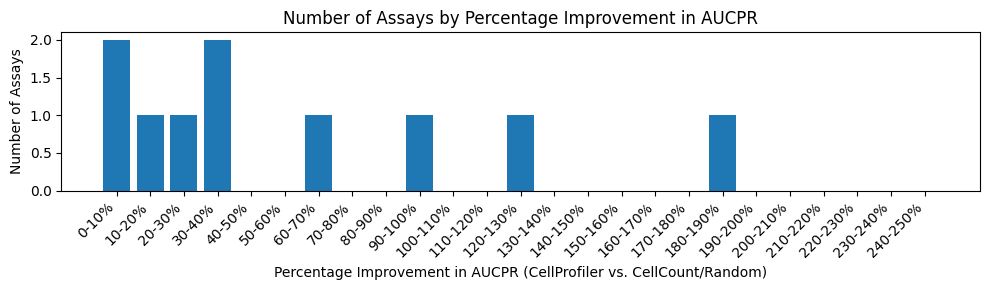

In [86]:
import matplotlib.pyplot as plt

# Calculate percentage improvement for CellProfiler AUCPR compared to max of CellCount/Random AUCPR
cellprofiler_df["Percentage_Improvement"] = (
    (cellprofiler_df["AUCPR"] - cellprofiler_df["Max_CellCount_Random_AUCPR"]) / cellprofiler_df["Max_CellCount_Random_AUCPR"]
) * 100


cellprofiler_df = cellprofiler_df.groupby("Task").mean().reset_index()

# Bin percentage improvement into ranges
bins = range(0, 251, 10)  # Define bins from 0% to 250% in increments of 10%
cellprofiler_df["Improvement_Bin"] = pd.cut(cellprofiler_df["Percentage_Improvement"], bins)

# Count the number of assays in each bin
improvement_counts = cellprofiler_df["Improvement_Bin"].value_counts().sort_index()

# Plotting
plt.figure(figsize=(10, 3))
plt.bar(
    [f"{int(interval.left)}-{int(interval.right)}%" for interval in improvement_counts.index],
    improvement_counts.values,
)
plt.xlabel("Percentage Improvement in AUCPR (CellProfiler vs. CellCount/Random)")
plt.ylabel("Number of Assays")
plt.title("Number of Assays by Percentage Improvement in AUCPR")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


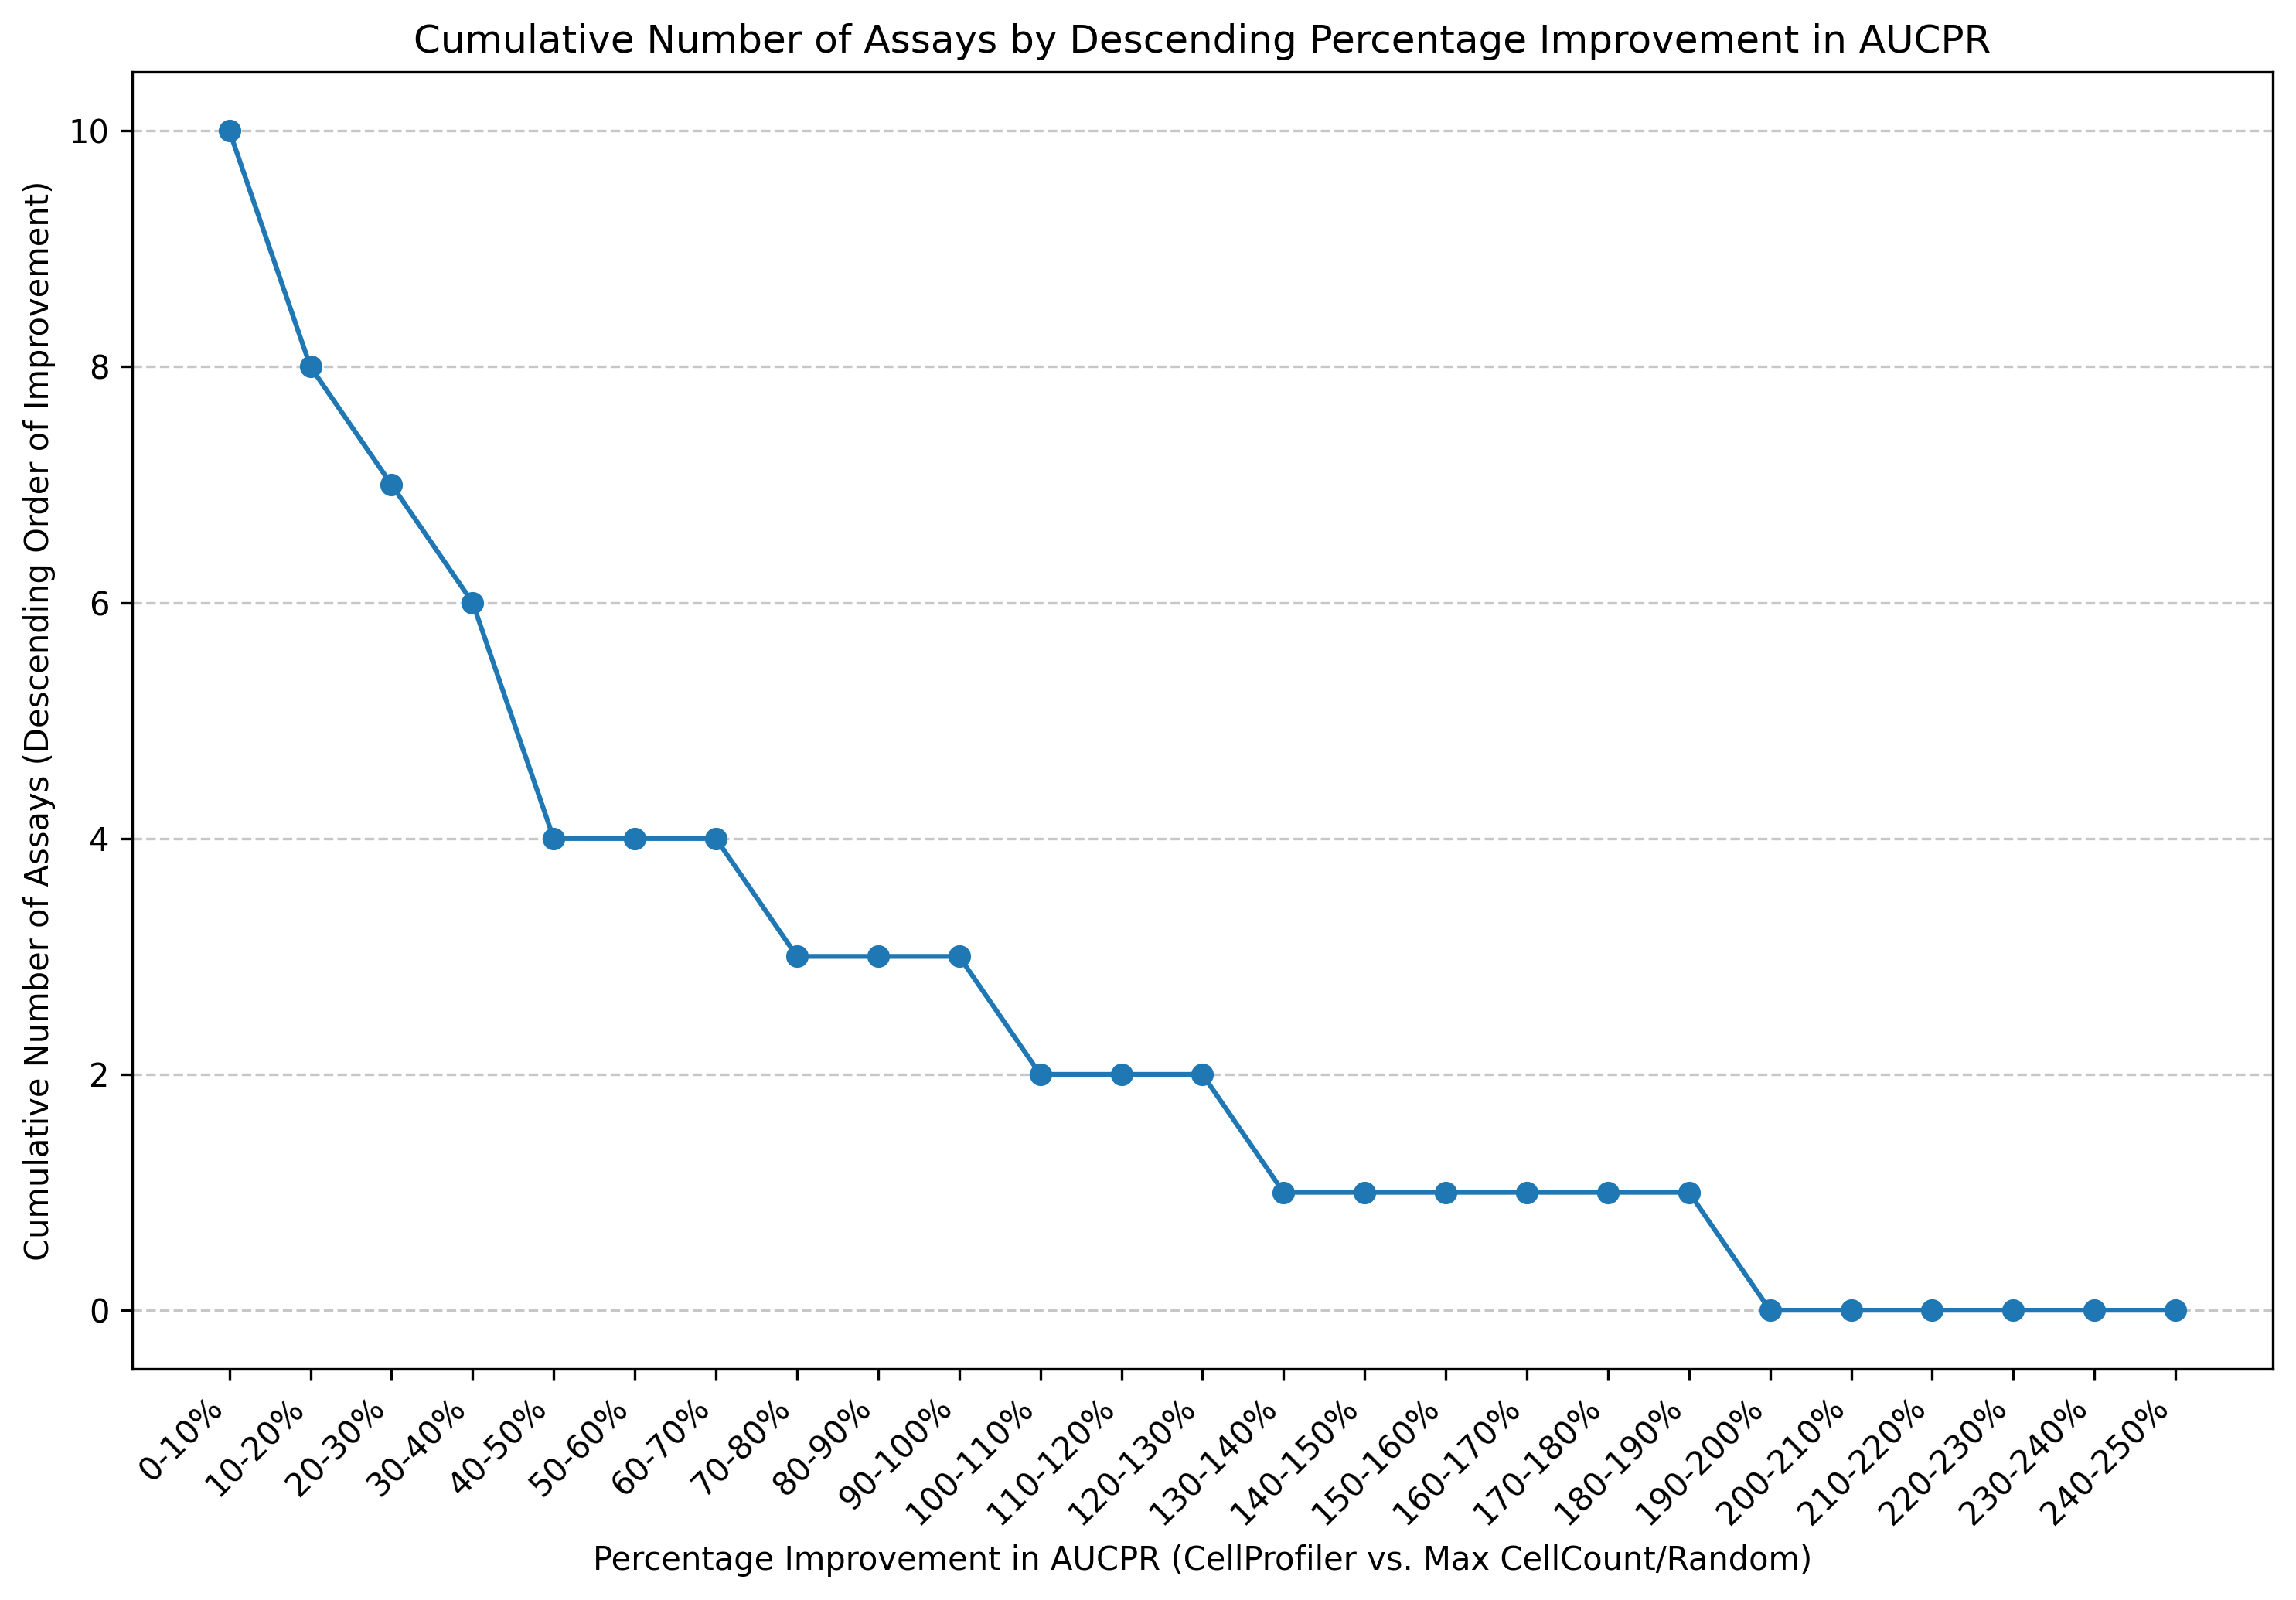

In [87]:
# Sort data for cumulative count starting from highest percentage improvement (100% to 0%)
reverse_cumulative_improvement = improvement_counts[::-1].cumsum()

# Line plot for reverse cumulative count of assays
plt.figure(figsize=(10, 7), dpi=300)
plt.plot(
    [f"{int(interval.left)}-{int(interval.right)}%" for interval in reverse_cumulative_improvement.index][::-1],
    reverse_cumulative_improvement.values[::-1],
    marker='o',
    linestyle='-'
)
plt.xlabel("Percentage Improvement in AUCPR (CellProfiler vs. Max CellCount/Random)")
plt.ylabel("Cumulative Number of Assays (Descending Order of Improvement)")
plt.title("Cumulative Number of Assays by Descending Percentage Improvement in AUCPR")
plt.xticks(rotation=45, ha="right")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


In [88]:
cellprofiler_df

,Task,Fold,AUC,Optimal Threshold,Optimal Kappa,Kappa,Kappa @ 0.50,Balanced Accuracy,AUCPR,Sensitivity,...,Total Actives Test,Total Inactives Test,Total Compounds Test,Scrambled Kappa,Scrambled Balanced Accuracy,Random_AUCPR,Max_CellCount_Random_AUCPR,Better_AUCPR,Percentage_Improvement,Improvement_Bin
0,ADRA1A_Antagonist,2.0,0.580074,0.326599,0.197995,0.020406,-0.024933,0.521408,0.271569,0.238095,...,14.000000,56.333333,70.333333,-0.009000,0.497076,0.199061,0.331444,0.333333,-10.763588,NaN
1,ADRA2A_Antagonist,2.0,0.658872,0.242424,0.125192,0.050257,0.000000,0.539846,0.163155,0.208333,...,8.333333,69.666667,78.000000,-0.007775,0.497619,0.106838,0.553419,0.000000,-70.522227,NaN
2,ADRA2B_Antagonist,2.0,0.502347,0.195286,0.091153,-0.010938,0.000000,0.487089,0.109796,0.166667,...,8.000000,71.000000,79.000000,0.000000,0.500000,0.101266,0.400844,0.000000,-61.466677,NaN
3,CAR_Antagonist,2.0,0.665996,0.272727,0.147866,0.047608,0.000000,0.528840,0.150450,0.095238,...,7.000000,71.000000,78.000000,0.000000,0.500000,0.089744,0.153377,0.333333,1.952325,"(0.0, 10.0]"
4,ERa_Antagonist,2.0,0.612083,0.343434,0.165440,0.180324,0.068399,0.570058,0.224907,0.166667,...,8.000000,75.333333,83.333333,0.000000,0.500000,0.096003,0.202073,0.666667,32.971614,"(30.0, 40.0]"
5,ERb_Antagonist,2.0,0.534874,0.235690,0.163155,0.070811,0.000000,0.544007,0.191597,0.266667,...,10.000000,72.666667,82.666667,0.000000,0.500000,0.120972,0.228438,0.333333,-8.369527,NaN
6,GPR119_Antagonist,2.0,0.495738,0.218855,0.086445,-0.061966,0.000000,0.454072,0.173292,0.125000,...,8.000000,67.666667,75.666667,0.000000,0.500000,0.105731,0.259715,0.333333,25.621956,"(20.0, 30.0]"
7,GR_Agonist,2.0,0.787636,0.309764,0.636426,0.637685,0.580604,0.805926,0.640730,0.636905,...,7.333333,79.666667,87.000000,-0.006843,0.497917,0.084291,0.130342,1.000000,428.674748,NaN
8,HCTR1_Antagonist,2.0,0.410148,0.121212,0.082518,-0.078203,0.000000,0.404390,0.180537,0.500000,...,7.666667,65.333333,73.000000,0.000000,0.500000,0.105023,0.107218,0.666667,61.951935,"(60.0, 70.0]"
9,PPARa_Antagonist,2.0,0.611572,0.259259,0.175087,0.085997,0.000000,0.547065,0.259936,0.261905,...,14.000000,71.666667,85.666667,0.000000,0.500000,0.163429,0.581715,0.000000,-55.316335,NaN


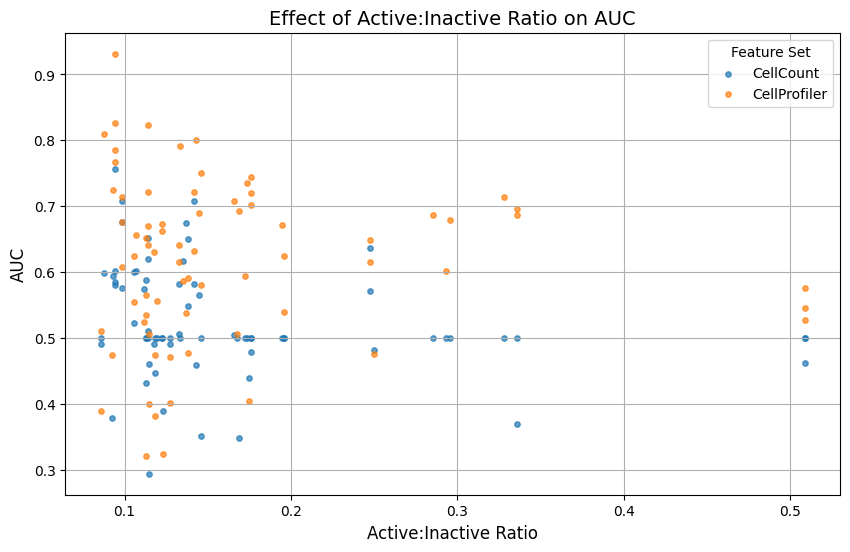

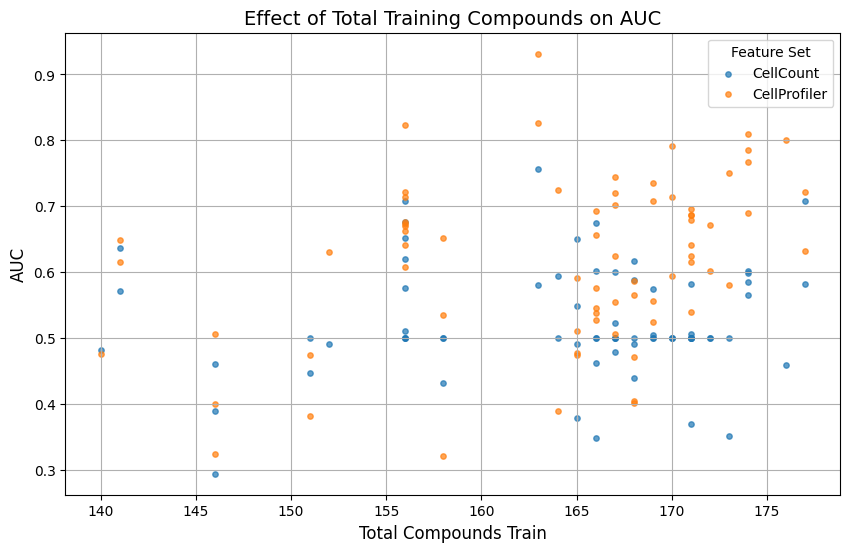

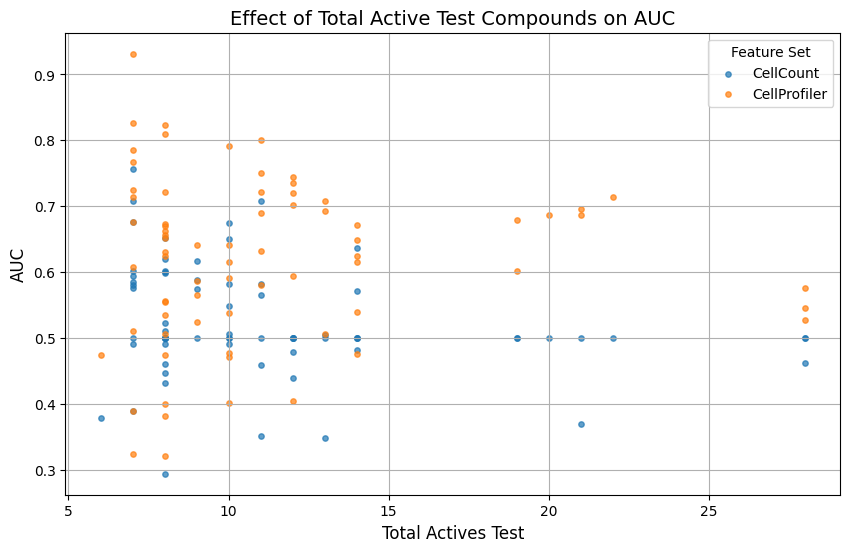

In [89]:
df = auc_df

# Adding a column for the ratio of actives to inactives in training data
df['Active:Inactive Ratio'] = df['Total Actives Train'] / df['Total Inactives Train']

# Plotting the relationship between Active:Inactive Ratio and AUC for each feature set
plt.figure(figsize=(10, 6))
for feature_set in df['Feature Set'].unique():
    subset = df[df['Feature Set'] == feature_set]
    plt.scatter(subset['Active:Inactive Ratio'], subset['AUC'], label=feature_set, s=15, alpha=0.7)

plt.title("Effect of Active:Inactive Ratio on AUC", fontsize=14)
plt.xlabel("Active:Inactive Ratio", fontsize=12)
plt.ylabel("AUC", fontsize=12)
plt.legend(title="Feature Set", fontsize=10)
plt.grid(True)
plt.show()

# Plotting the relationship between total training compounds and AUC for each feature set
plt.figure(figsize=(10, 6))
for feature_set in df['Feature Set'].unique():
    subset = df[df['Feature Set'] == feature_set]
    plt.scatter(subset['Total Compounds Train'], subset['AUC'], label=feature_set, s=15, alpha=0.7)

plt.title("Effect of Total Training Compounds on AUC", fontsize=14)
plt.xlabel("Total Compounds Train", fontsize=12)
plt.ylabel("AUC", fontsize=12)
plt.legend(title="Feature Set", fontsize=10)
plt.grid(True)
plt.show()

# Plotting the relationship between total training compounds and AUC for each feature set
plt.figure(figsize=(10, 6))
for feature_set in df['Feature Set'].unique():
    subset = df[df['Feature Set'] == feature_set]
    plt.scatter(subset['Total Actives Test'], subset['AUC'], label=feature_set, s=15, alpha=0.7)

plt.title("Effect of Total Active Test Compounds on AUC", fontsize=14)
plt.xlabel("Total Actives Test", fontsize=12)
plt.ylabel("AUC", fontsize=12)
plt.legend(title="Feature Set", fontsize=10)
plt.grid(True)
plt.show()

In [90]:
summary_stats

,Task,Feature Set,mean,std,count
0,ADRA1A_Antagonist,CellCount,0.563242,0.077289,3
1,ADRA1A_Antagonist,CellProfiler,0.580074,0.091599,3
2,ADRA2A_Antagonist,CellCount,0.500000,0.000000,3
3,ADRA2A_Antagonist,CellProfiler,0.658872,0.016459,3
4,ADRA2B_Antagonist,CellCount,0.477113,0.039642,3
5,ADRA2B_Antagonist,CellProfiler,0.502347,0.167922,3
6,CAR_Antagonist,CellCount,0.653253,0.069273,3
7,CAR_Antagonist,CellProfiler,0.665996,0.054027,3
8,ERa_Antagonist,CellCount,0.575102,0.044844,3
9,ERa_Antagonist,CellProfiler,0.612083,0.051846,3


In [91]:
summary_stats.Task.nunique()

24

In [92]:
overall_comparison

,Feature Set,mean,std
0,CellCount,0.524407,0.085522
1,CellProfiler,0.618041,0.125979


p-value annotation legend:
ns: 5.00e-02 < p <= 1.00e+00
*: 1.00e-02 < p <= 5.00e-02
**: 1.00e-03 < p <= 1.00e-02
***: 1.00e-04 < p <= 1.00e-03
****: p <= 1.00e-04

CellCount v.s. CellProfiler: t-test independent samples with Bonferroni correction, P_val=2.937e-05 stat=-4.318e+00


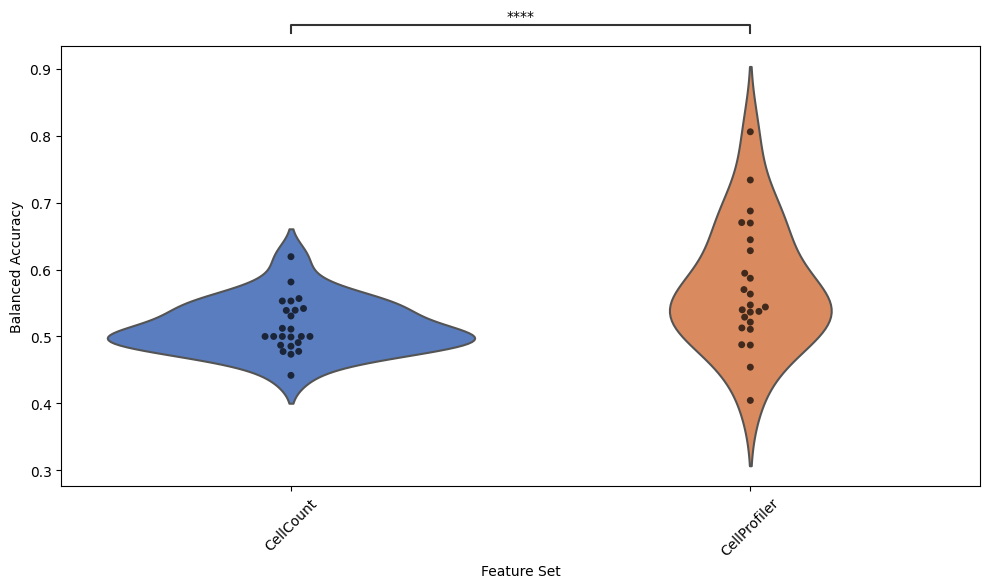

In [93]:
import matplotlib.pyplot as plt
import seaborn as sns
from statannot import add_stat_annotation


# Create the violin plot with swarm overlay
plt.figure(figsize=(10, 6))
ax = sns.violinplot(x="Feature Set", y="Balanced Accuracy", data=auc_df.groupby(["Task","Feature Set"]).mean().reset_index(), inner=None, palette="muted")
sns.swarmplot(x="Feature Set", y="Balanced Accuracy", data=auc_df.groupby(["Task","Feature Set"]).mean().reset_index(), color="k", alpha=0.7)

# Add statistical annotations
add_stat_annotation(ax, data=auc_df, x="Feature Set", y="Balanced Accuracy",
                    box_pairs=[("CellCount", "CellProfiler")],
                    test="t-test_ind", text_format="star", loc="outside", verbose=2)

# Customize the plot
plt.xlabel("Feature Set")
plt.ylabel("Balanced Accuracy")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


p-value annotation legend:
ns: 5.00e-02 < p <= 1.00e+00
*: 1.00e-02 < p <= 5.00e-02
**: 1.00e-03 < p <= 1.00e-02
***: 1.00e-04 < p <= 1.00e-03
****: p <= 1.00e-04

CellCount v.s. CellProfiler: t-test independent samples with Bonferroni correction, P_val=6.287e-07 stat=-5.218e+00


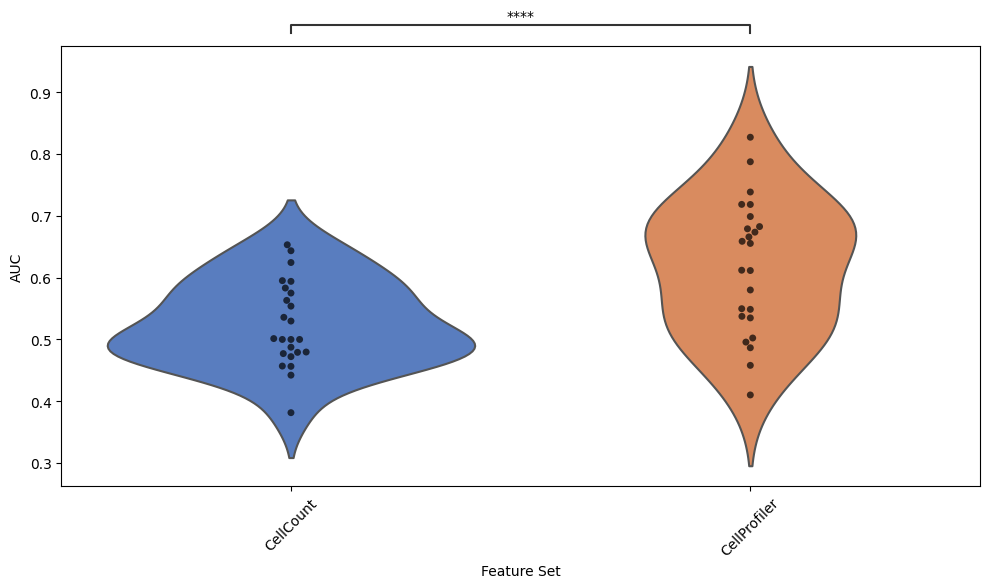

In [94]:
import matplotlib.pyplot as plt
import seaborn as sns
from statannot import add_stat_annotation


# Create the violin plot with swarm overlay
plt.figure(figsize=(10, 6))
ax = sns.violinplot(x="Feature Set", y="AUC", data=auc_df.groupby(["Task","Feature Set"]).mean().reset_index(), inner=None, palette="muted")
sns.swarmplot(x="Feature Set", y="AUC", data=auc_df.groupby(["Task","Feature Set"]).mean().reset_index(), color="k", alpha=0.7)

# Add statistical annotations
add_stat_annotation(ax, data=auc_df, x="Feature Set", y="AUC",
                    box_pairs=[("CellCount", "CellProfiler")],
                    test="t-test_ind", text_format="star", loc="outside", verbose=2)

# Customize the plot
plt.xlabel("Feature Set")
plt.ylabel("AUC")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [95]:
df_meta_type = pd.read_csv("data/bundle_table.csv")
df_meta_type["Task"] = df_meta_type["Target_ID"] + "_" + df_meta_type["Mode"]

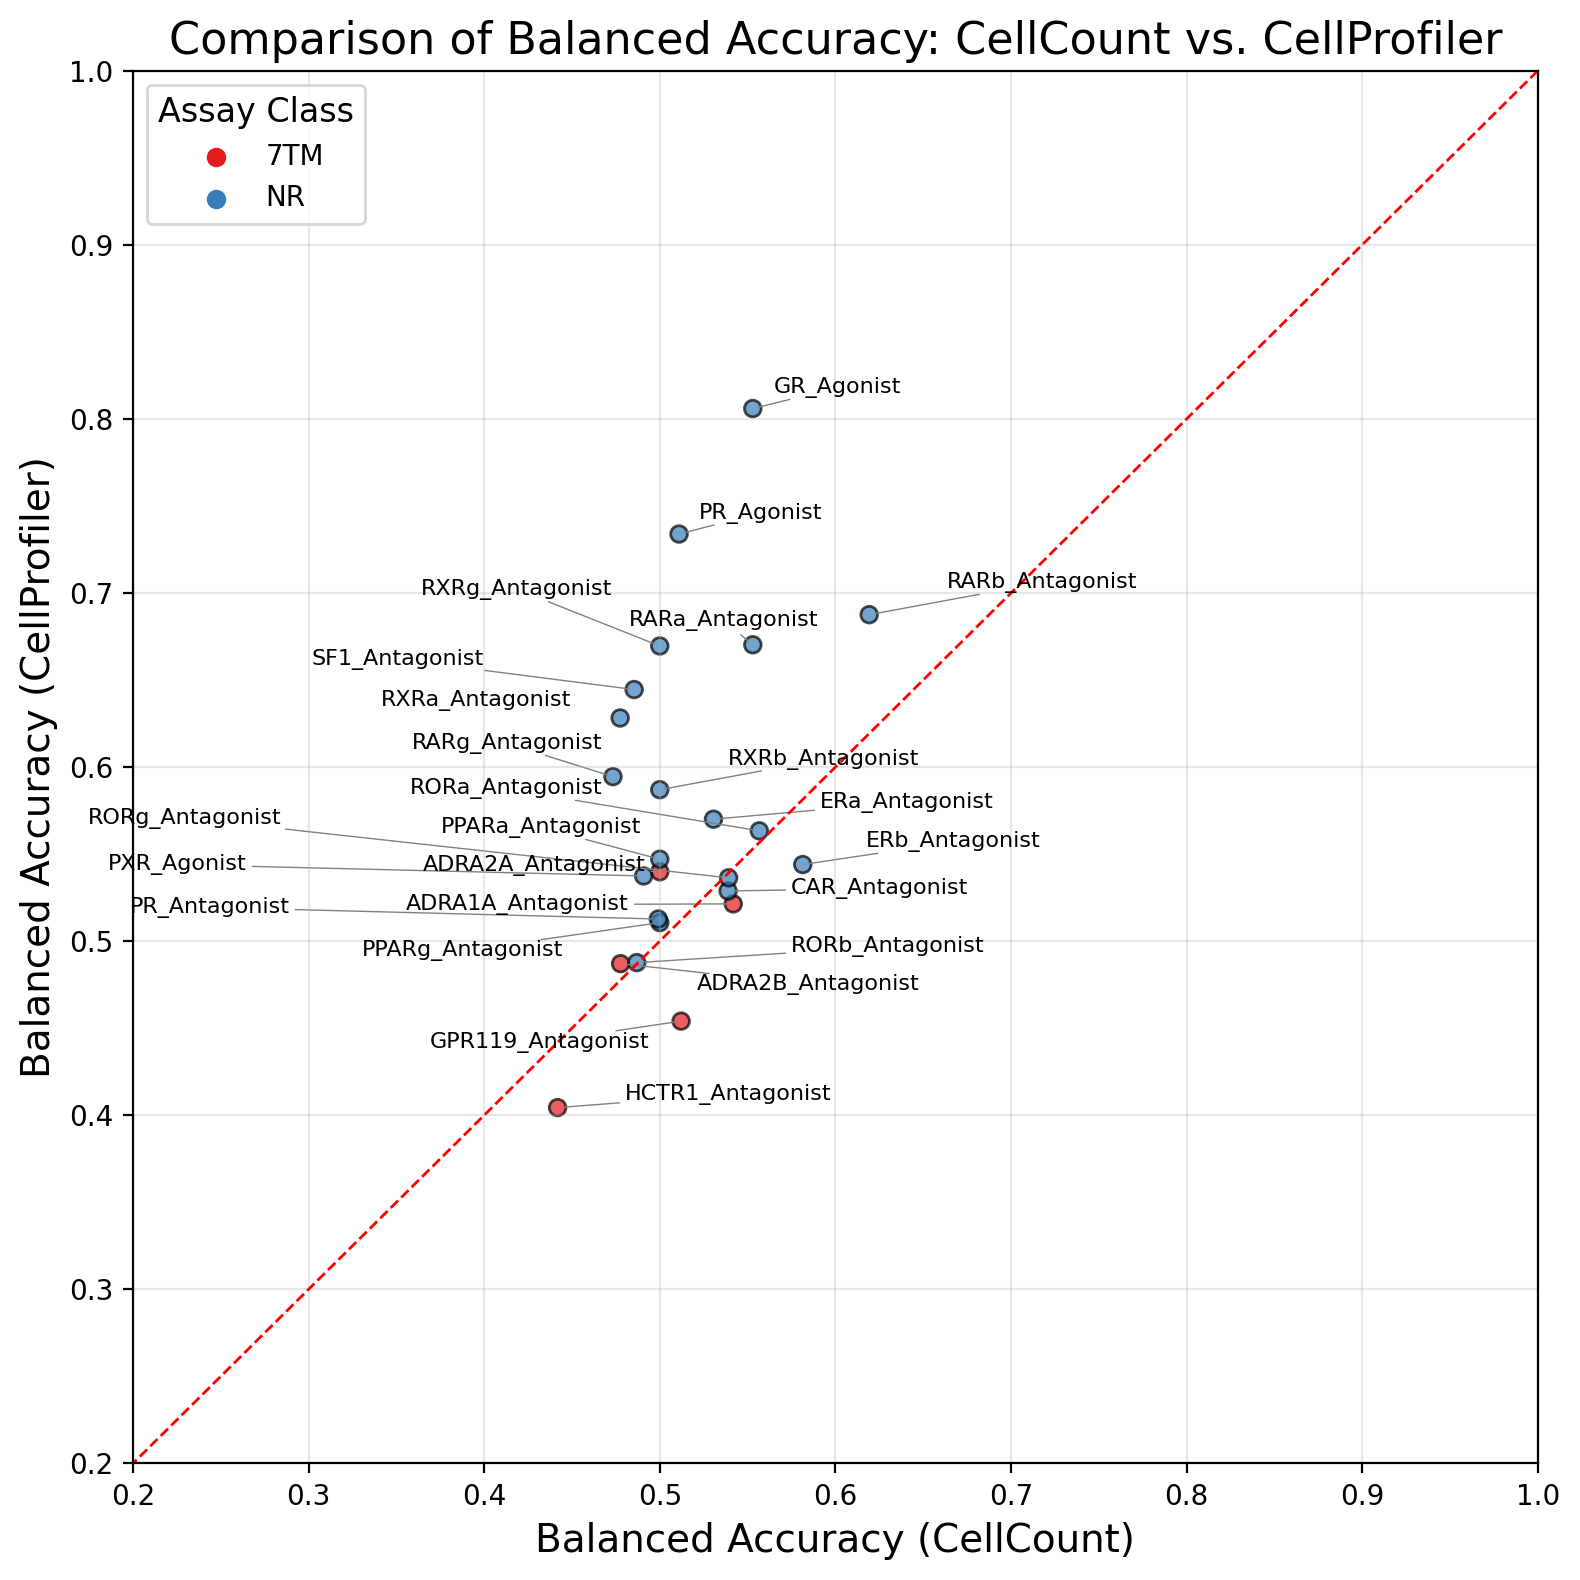

In [101]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from adjustText import adjust_text

# Prepare the data
cellcount_data = auc_df[auc_df["Feature Set"] == "CellCount"].groupby(["Task", "Feature Set"]).mean().reset_index()
cellprofiler_data = auc_df[auc_df["Feature Set"] == "CellProfiler"].groupby(["Task", "Feature Set"]).mean().reset_index()

# Merge the data on Task
merged_data = pd.merge(cellcount_data, cellprofiler_data, on="Task", suffixes=("_CellCount", "_CellProfiler"))
merged_data = pd.merge(merged_data, df_meta_type, on="Task")  # assuming df_meta_type has "Task" and "Class"

# Assign colors by class
palette = sns.color_palette("Set1", n_colors=merged_data["Class"].nunique())
class_colors = dict(zip(merged_data["Class"].unique(), palette))
merged_data["Color"] = merged_data["Class"].map(class_colors)

# Plot
plt.figure(figsize=(8, 8), dpi=200)
plt.scatter(
    merged_data["Balanced Accuracy_CellCount"],
    merged_data["Balanced Accuracy_CellProfiler"],
    alpha=0.7,
    edgecolors="k",
    c=merged_data["Color"]
)

# Add the x=y line
plt.plot([0, 1], [0, 1], color="red", linestyle="--", linewidth=1)

# Add text labels with adjustment
texts = []
for i, row in merged_data.iterrows():
    texts.append(
        plt.text(
            row["Balanced Accuracy_CellCount"],
            row["Balanced Accuracy_CellProfiler"],
            row["Task"],
            fontsize=8,
            ha='right'
        )
    )
adjust_text(texts, arrowprops=dict(arrowstyle="-", color='gray', lw=0.5))

# Add custom legend
for cls in merged_data["Class"].unique():
    plt.scatter([], [], color=class_colors[cls], label=cls)
plt.legend(title="Assay Class", fontsize=10, title_fontsize=12)

# Customize
plt.title("Comparison of Balanced Accuracy: CellCount vs. CellProfiler", fontsize=16)
plt.xlabel("Balanced Accuracy (CellCount)", fontsize=14)
plt.ylabel("Balanced Accuracy (CellProfiler)", fontsize=14)
plt.grid(alpha=0.3)
plt.xlim(0.2, 1)
plt.ylim(0.2, 1)
plt.tight_layout()
plt.show()


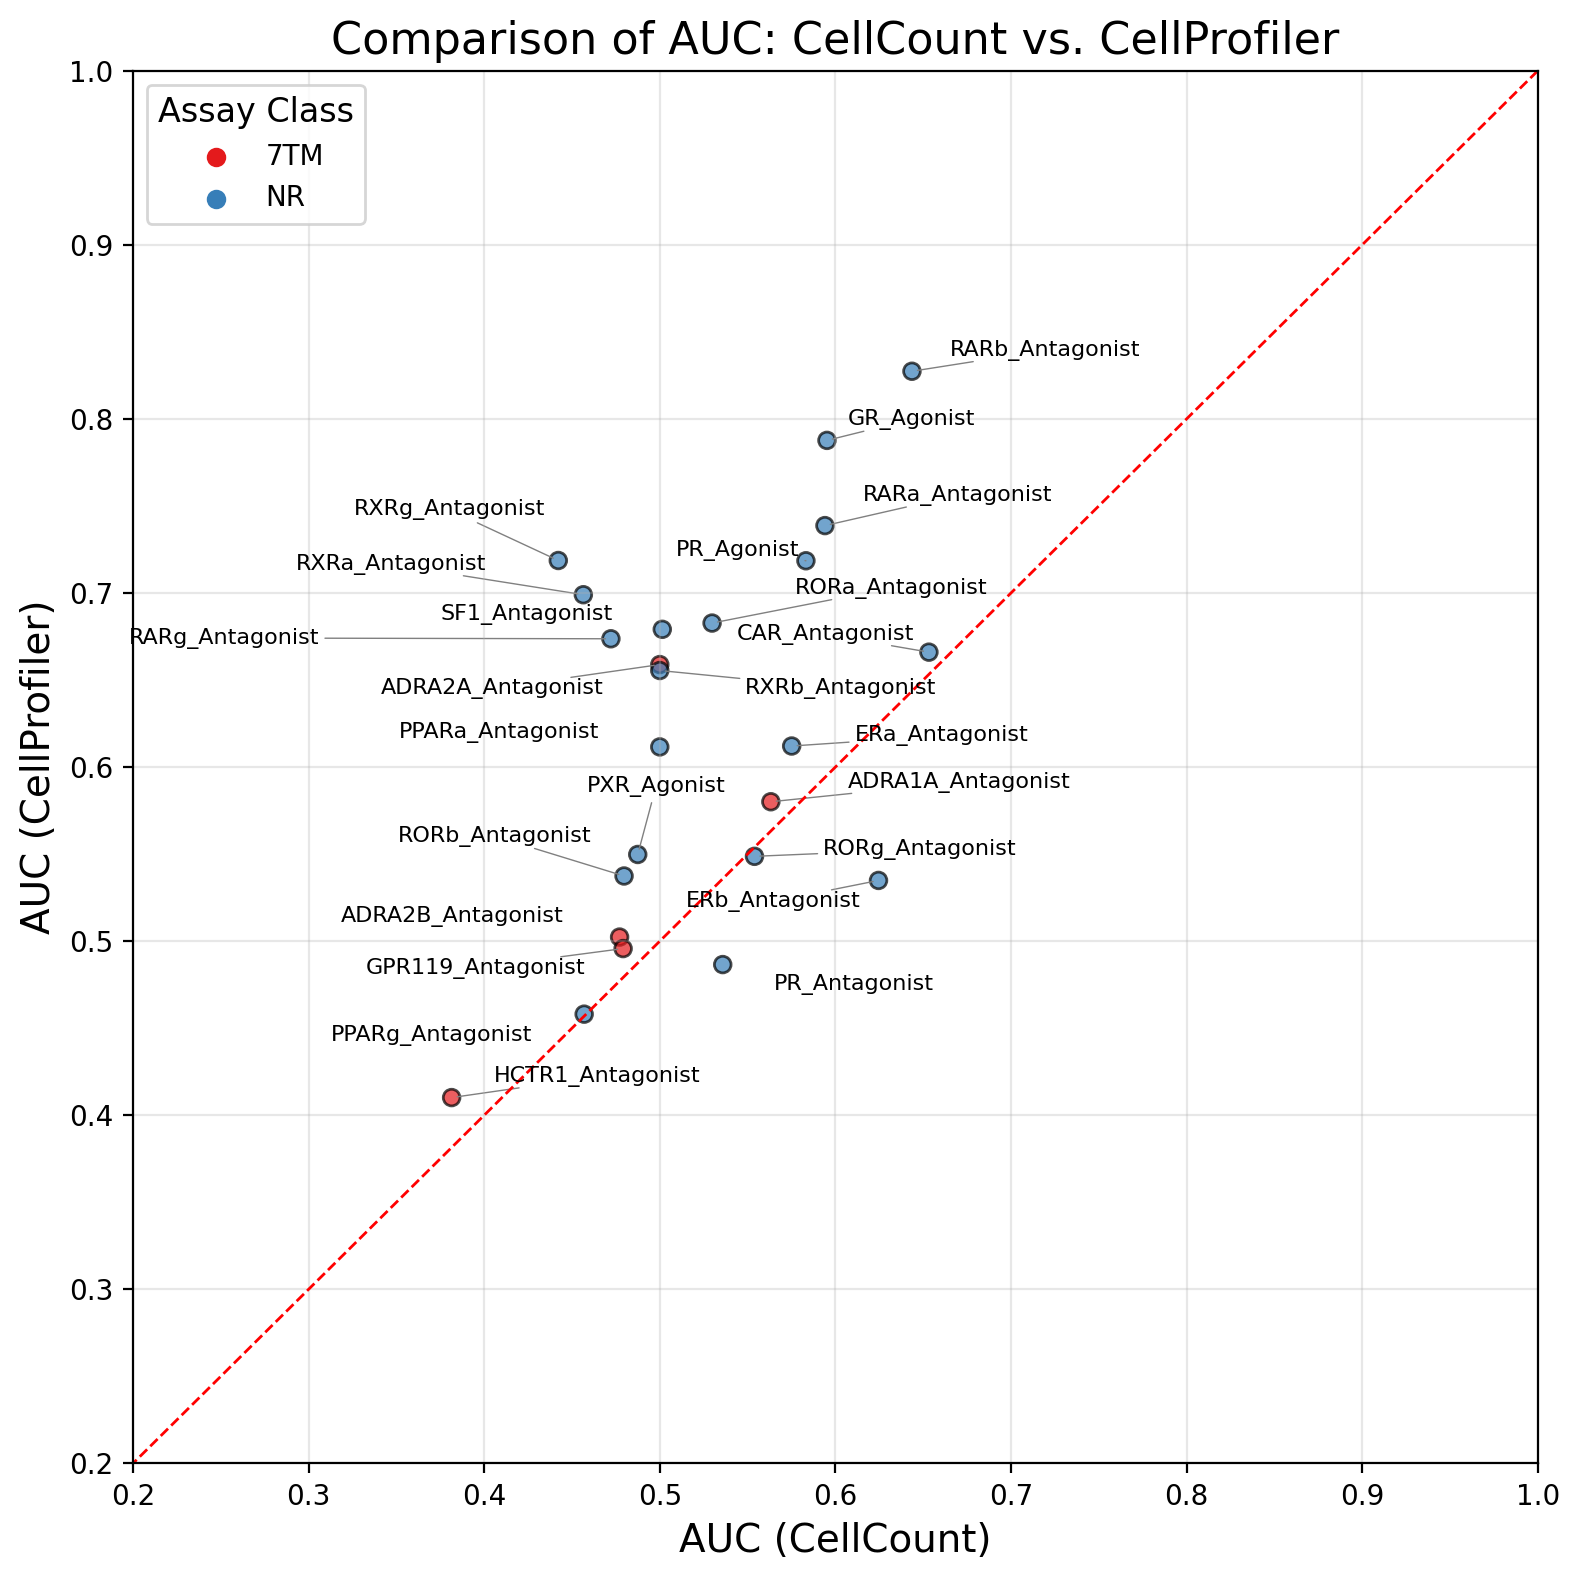

In [102]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from adjustText import adjust_text

# Prepare the data
cellcount_data = auc_df[auc_df["Feature Set"] == "CellCount"].groupby(["Task", "Feature Set"]).mean().reset_index()
cellprofiler_data = auc_df[auc_df["Feature Set"] == "CellProfiler"].groupby(["Task", "Feature Set"]).mean().reset_index()

# Merge the data on Task
merged_data = pd.merge(cellcount_data, cellprofiler_data, on="Task", suffixes=("_CellCount", "_CellProfiler"))
merged_data = pd.merge(merged_data, df_meta_type, on="Task")  # assuming df_meta_type has "Task" and "Class"

# Assign colors by class
palette = sns.color_palette("Set1", n_colors=merged_data["Class"].nunique())
class_colors = dict(zip(merged_data["Class"].unique(), palette))
merged_data["Color"] = merged_data["Class"].map(class_colors)

# Plot
plt.figure(figsize=(8, 8), dpi=200)
plt.scatter(
    merged_data["AUC_CellCount"],
    merged_data["AUC_CellProfiler"],
    alpha=0.7,
    edgecolors="k",
    c=merged_data["Color"]
)

# Add the x=y line
plt.plot([0, 1], [0, 1], color="red", linestyle="--", linewidth=1)

# Add text labels with adjustment
texts = []
for i, row in merged_data.iterrows():
    texts.append(
        plt.text(
            row["AUC_CellCount"],
            row["AUC_CellProfiler"],
            row["Task"],
            fontsize=8,
            ha='right'
        )
    )
adjust_text(texts, arrowprops=dict(arrowstyle="-", color='gray', lw=0.5))

# Add custom legend
for cls in merged_data["Class"].unique():
    plt.scatter([], [], color=class_colors[cls], label=cls)
plt.legend(title="Assay Class", fontsize=10, title_fontsize=12)

# Customize
plt.title("Comparison of AUC: CellCount vs. CellProfiler", fontsize=16)
plt.xlabel("AUC (CellCount)", fontsize=14)
plt.ylabel("AUC (CellProfiler)", fontsize=14)
plt.grid(alpha=0.3)
plt.xlim(0.2, 1)
plt.ylim(0.2, 1)
plt.tight_layout()
plt.show()


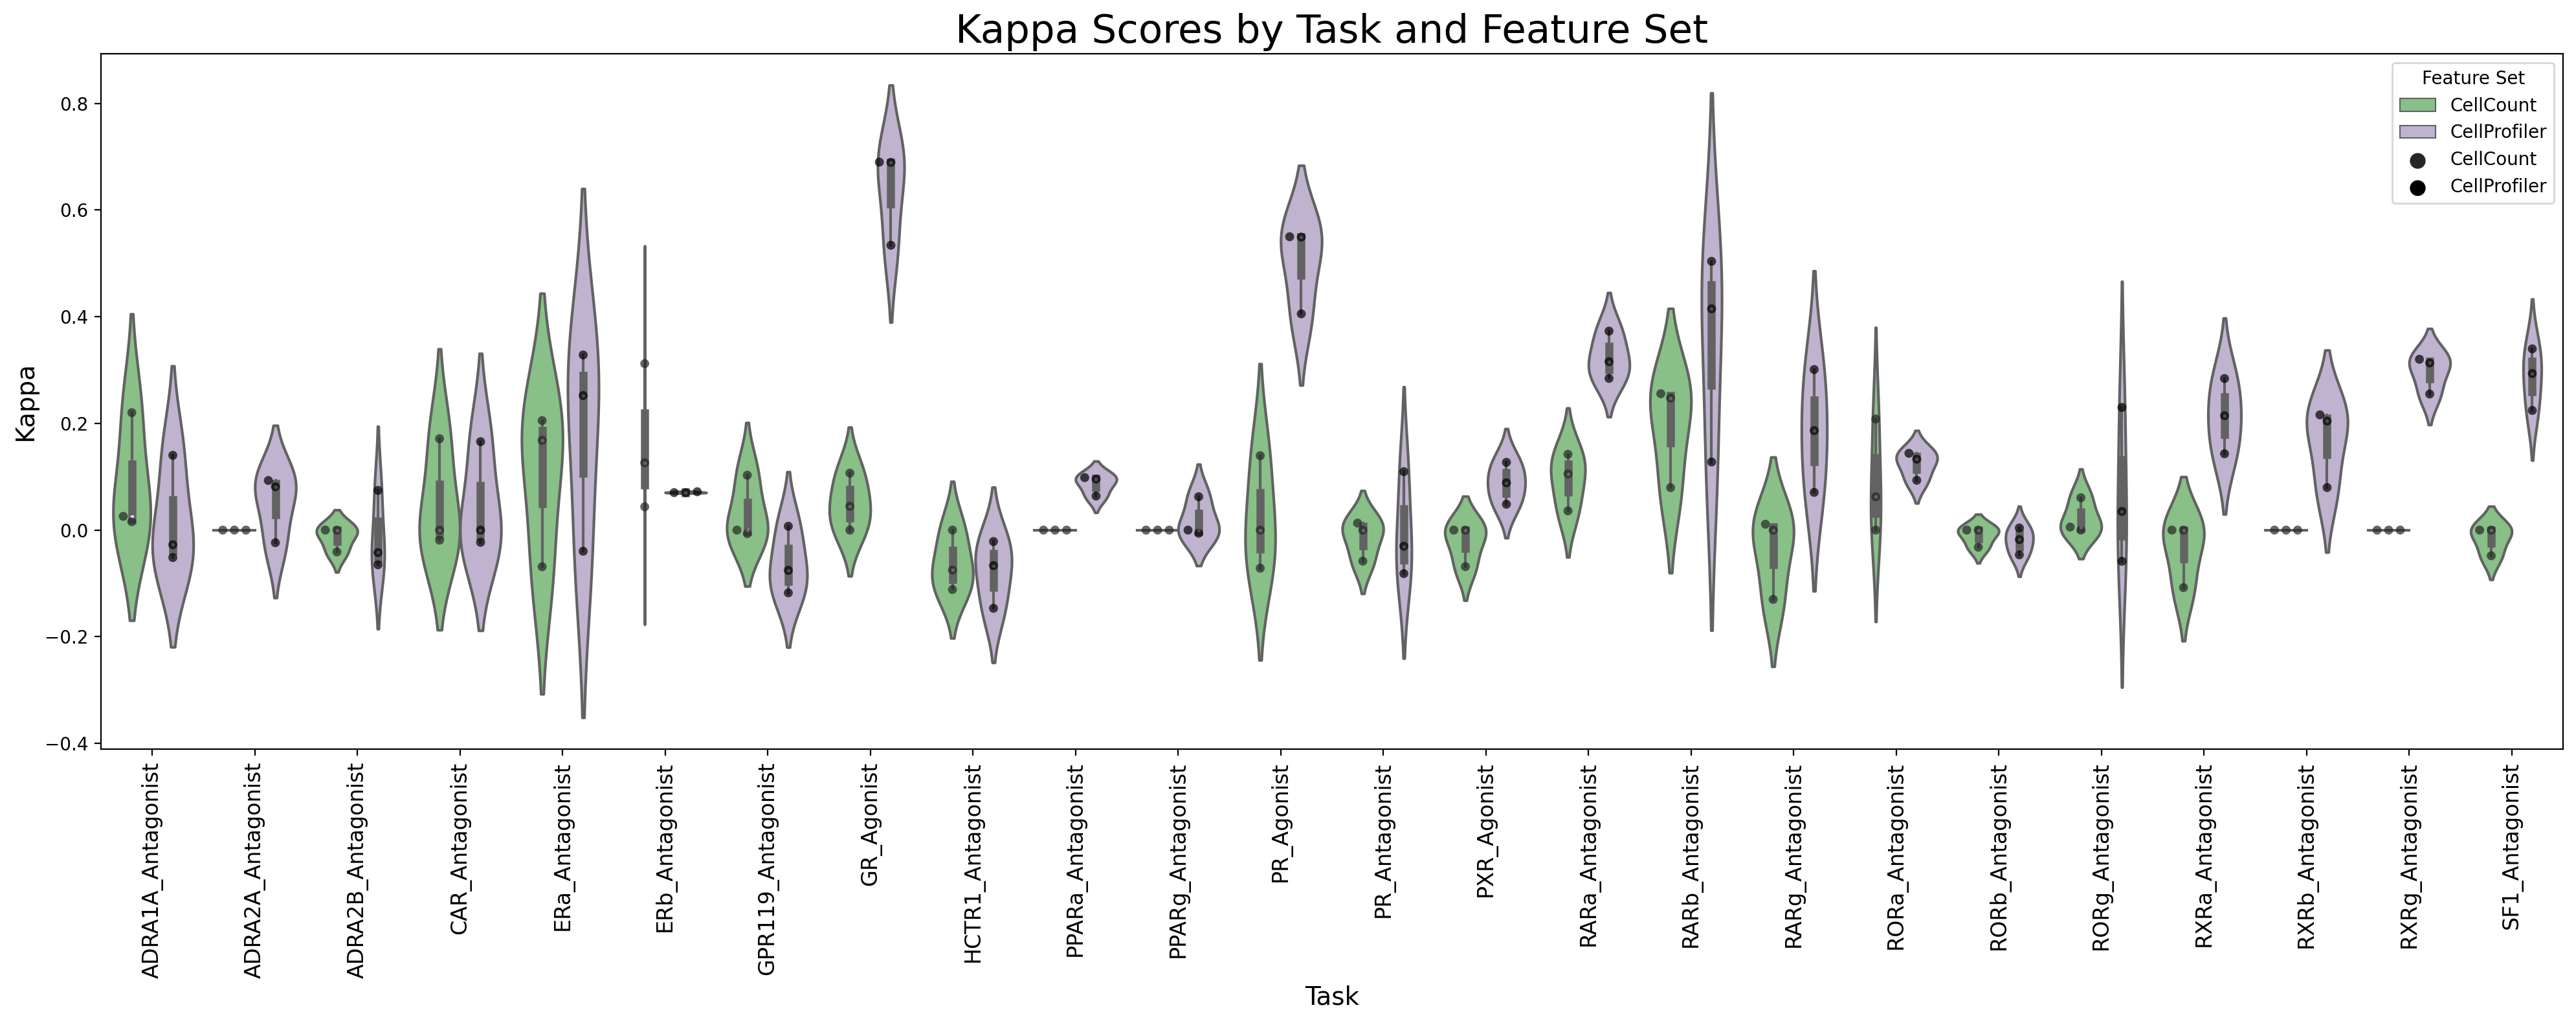

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns


# Create the violin plot with swarm overlay
plt.figure(figsize=(20, 8), dpi=200)
sns.violinplot(x="Task", y="Kappa", hue="Feature Set", data=auc_df, palette="Accent", dodge=True)
plt.legend(title="Feature Set", fontsize=12)

sns.swarmplot(x="Task", y="Kappa", hue="Feature Set", data=auc_df, color="k", alpha=0.7, dodge=True)

# Customize the plot
plt.title("Kappa Scores by Task and Feature Set", fontsize=22)
plt.xlabel("Task", fontsize=14)
plt.ylabel("Kappa", fontsize=14)
plt.xticks(rotation=90, fontsize=12)
plt.tight_layout()
plt.show()
